# 03 — KPI Calculations
**Week 3 — CadetX Heavy Supplier, Inventory & Warehouse Analytics**
**Scope:** Sales, customer, product, inventory, warehouse & supplier KPIs
**Source:** `merged_dataset.csv` (2019–2024) — 130,402 rows, 20,000 unique orders, 89 columns,
rebuilt from the 10 raw source tables with supplier data joined in

---
# Part A — Sales & Customer KPIs

In [1]:
import pandas as pd

sales_df = pd.read_csv("merged_dataset_ALL.csv", low_memory=False)
sales_df["order_date"] = pd.to_datetime(sales_df["order_date"], errors="coerce")
sales_df["delivery_date"] = pd.to_datetime(sales_df["delivery_date"], errors="coerce")
print(sales_df.shape)
sales_df.head()

(130402, 89)


,so_id,line_number,product_id,quantity,unit_price,gst_rate,line_total,gst_amount,line_grand_total,customer_id,...,supplier_pincode,supplier_lead_time_days,reliability_score,import_duty_rate,china_tax_id,invoice_id,invoice_date,due_date,invoice_grand_total,payment_status
0,SO-990591,1,P018,19,11300,28,214700,60116.0,274816.0,C0070,...,885785,10,3,15,64SHANGH737801,INV-325361,2022-05-28,2022-06-27,1720159.6,Unpaid
1,SO-990591,2,P026,2,310,18,620,111.6,731.6,C0070,...,202099,12,5,15,41GUANGZ551261,INV-325361,2022-05-28,2022-06-27,1720159.6,Unpaid
2,SO-990591,3,P026,3,310,18,930,167.4,1097.4,C0070,...,202099,12,5,15,41GUANGZ551261,INV-325361,2022-05-28,2022-06-27,1720159.6,Unpaid
3,SO-990591,4,P013,9,1450,18,13050,2349.0,15399.0,C0070,...,586808,19,5,8,90SUZHOU398241,INV-325361,2022-05-28,2022-06-27,1720159.6,Unpaid
4,SO-990591,5,P004,3,39800,28,119400,33432.0,152832.0,C0070,...,202099,12,5,15,41GUANGZ551261,INV-325361,2022-05-28,2022-06-27,1720159.6,Unpaid


## A.1 Build order-level view

The source file is at line-item grain (one row per product per order). Revenue KPIs are computed
at **order level** (one row per `so_id`) to avoid double-counting order totals across line items.

In [2]:
order_level = sales_df.drop_duplicates(subset=["so_id"]).copy()
order_level["lead_time_days"] = (order_level["delivery_date"] - order_level["order_date"]).dt.days
order_level["order_month"] = order_level["order_date"].dt.to_period("M").dt.to_timestamp()
order_level["order_year"] = order_level["order_date"].dt.year
print(f"Unique orders: {order_level['so_id'].nunique():,}")

Unique orders: 20,000


## A.2 Top-line KPIs

In [3]:
total_revenue = order_level["grand_total"].sum()
avg_order_value = order_level["grand_total"].mean()
total_orders = order_level["so_id"].nunique()

print(f"Total Revenue: ₹{total_revenue:,.2f}")
print(f"Average Order Value: ₹{avg_order_value:,.2f}")
print(f"Total Orders: {total_orders:,}")

Total Revenue: ₹32,424,754,555.80
Average Order Value: ₹1,621,237.73
Total Orders: 20,000


## A.3 Revenue by year, customer type, and region

In [4]:
rev_by_year = order_level.groupby("order_year")["grand_total"].sum().round(2)
rev_by_month = order_level.groupby("order_month")["grand_total"].sum().round(2)
rev_by_year

order_year
2019    5.403206e+09
2020    5.503238e+09
2021    5.415991e+09
2022    5.411518e+09
2023    5.394009e+09
2024    5.296793e+09
Name: grand_total, dtype: float64

In [5]:
cust_type = order_level.groupby("customer_type").agg(
    total_revenue=("grand_total", "sum"),
    avg_order_value=("grand_total", "mean"),
    order_count=("so_id", "nunique")
).round(2).sort_values("total_revenue", ascending=False)
cust_type

,total_revenue,avg_order_value,order_count
customer_type,,,
Government,7.213891e+09,1585122.24,4551
Corporate,6.632427e+09,1631994.78,4064
Dealer,6.607097e+09,1645193.45,4016
Fleet Owner,6.223974e+09,1623363.14,3834
Retail,5.747365e+09,1625845.90,3535


In [6]:
region_rev = order_level.groupby("customer_region").agg(
    total_revenue=("grand_total", "sum"),
    order_count=("so_id", "nunique")
).round(2).sort_values("total_revenue", ascending=False)
region_rev

,total_revenue,order_count
customer_region,,
South,1.033107e+10,6384
West,9.506449e+09,5923
East,5.688253e+09,3491
North,5.536616e+09,3333
Central,7.018619e+08,447
North East,6.605066e+08,422


## A.4 Delivery lead time (order date → delivery date)

Negative lead times (data artifacts where delivery predates the order) are excluded.

In [7]:
valid_lead = order_level["lead_time_days"].dropna()
valid_lead = valid_lead[valid_lead >= 0]

print(f"Average lead time: {valid_lead.mean():.2f} days")
print(f"Median lead time: {valid_lead.median():.1f} days")

lead_by_region = order_level[order_level["lead_time_days"] >= 0].groupby("customer_region")["lead_time_days"].mean().round(2)
lead_by_region

Average lead time: 8.06 days
Median lead time: 8.0 days


customer_region
Central       7.56
East          7.90
North         8.03
North East    7.80
South         8.13
West          8.15
Name: lead_time_days, dtype: float64

## A.5 Top 10 products by revenue

Computed at line-item level, since `product_name` only exists at that grain.

In [8]:
top_products = sales_df.groupby("product_name").agg(
    total_revenue=("line_grand_total", "sum"),
    units_sold=("quantity", "sum")
).round(2).sort_values("total_revenue", ascending=False).head(10)
top_products

,total_revenue,units_sold
product_name,,
Engine Block EB-600,6.888215e+09,45222
Transmission Assembly TA-800,4.813341e+09,45035
Boom Cylinder BC-400,2.741782e+09,46364
Swing Motor SWM-350,2.341947e+09,45971
Track Chain TC-45,2.321773e+09,45575
Turbocharger TB-900,2.097976e+09,46964
Hydraulic Cylinder HC-200,1.646709e+09,46612
Hydraulic Pump HP-300,1.423399e+09,45389
Fuel Pump FP-350,1.286585e+09,45897


## A.6 Payment status breakdown

Includes the "Not Invoiced" label applied for orders without a matching invoice.

In [9]:
pay_status = order_level["payment_status"].fillna("Not Invoiced").value_counts()
pay_status_pct = (pay_status / pay_status.sum() * 100).round(1)
pay_summary = pd.DataFrame({"order_count": pay_status, "pct_of_orders": pay_status_pct})
pay_summary

,order_count,pct_of_orders
payment_status,,
Paid,12264,61.3
Partially Paid,3578,17.9
Not Invoiced,2360,11.8
Unpaid,1798,9.0


## A.7 Exploratory charts (sales/customer)

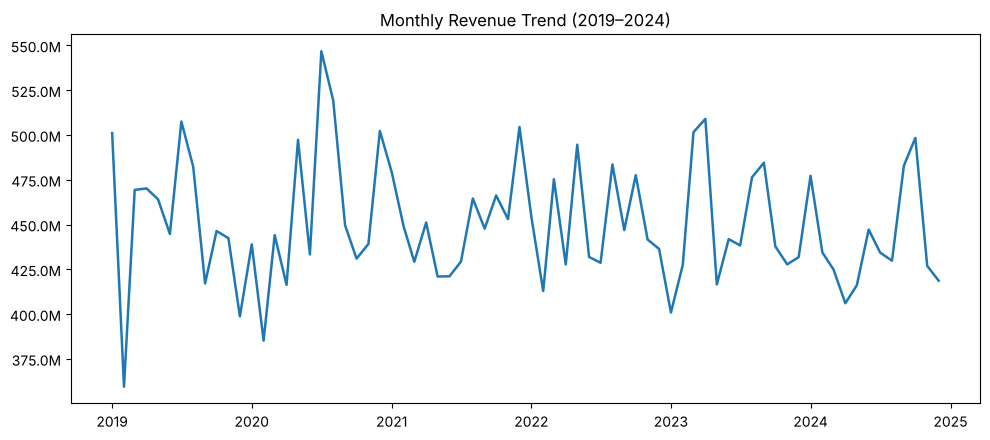

In [10]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(rev_by_month.index, rev_by_month.values, linewidth=1.8)
ax.set_title("Monthly Revenue Trend (2019–2024)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))
plt.tight_layout()
plt.show()

---
# Part B — Product, Inventory & Warehouse KPIs

In [11]:
inv_df = sales_df.copy()
print(inv_df.shape)

(130402, 89)


## B.1 Data-quality check: stock field scales

`current_stock` is compared against `max_stock`, `reorder_level`, and `safety_stock` to confirm
they are on comparable scales before using them together.

In [12]:
scale_check = inv_df[["current_stock", "max_stock", "reorder_level", "safety_stock"]].describe().round(2)
scale_check

,current_stock,max_stock,reorder_level,safety_stock
count,130402.00,130402.00,130402.00,130402.00
mean,107100.75,323.67,64.92,45.38
std,5327.10,117.31,24.15,16.91
min,88853.00,131.00,24.00,16.00
25%,103464.00,231.00,44.00,31.00
50%,107584.00,311.00,62.00,43.00
75%,110681.00,422.00,83.00,58.00
max,121013.00,582.00,119.00,85.00


**Finding:** `current_stock` sits in the ~88,000–121,000 range, while `max_stock` /
`reorder_level` / `safety_stock` sit in the tens-to-low-hundreds range. A direct comparison
(`current_stock` vs. `max_stock`) would mark every row as "Overstock," so it is not usable as-is.
This is flagged for the Data Analyst to confirm which figure is correct, or whether these fields
represent different units/aggregation levels. A quantile-based classification is used below as an
interim measure.

## B.2 Inventory turnover per product

In [13]:
inventory_kpi = inv_df.groupby(["product_id", "category", "product_name"]).agg(
    total_units_sold=("quantity", "sum"),
    avg_inventory_level=("current_stock", "mean"),
).reset_index()
inventory_kpi["avg_inventory_level"] = inventory_kpi["avg_inventory_level"].round(2)
inventory_kpi["inventory_turnover_ratio"] = (
    inventory_kpi["total_units_sold"] / inventory_kpi["avg_inventory_level"]
).round(2)
inventory_kpi = inventory_kpi.sort_values("inventory_turnover_ratio", ascending=False).reset_index(drop=True)
inventory_kpi.head(10)

,product_id,category,product_name,total_units_sold,avg_inventory_level,inventory_turnover_ratio
0,P029,Sensors,Pressure Sensor PS-90,47066,105392.54,0.45
1,P019,Hydraulic,Swing Motor SWM-350,45971,103144.74,0.45
2,P016,Cooling,Radiator RD-250,46306,105805.84,0.44
3,P021,Hydraulic,Boom Cylinder BC-400,46364,104712.51,0.44
4,P027,Seals,O-Ring Set OR-50,45678,104697.95,0.44
5,P028,Electrical,Light Assembly LA-18,46164,104000.25,0.44
6,P030,Engine,Fuel Pump FP-350,45897,105259.62,0.44
7,P015,Engine,Engine Block EB-600,45222,105420.16,0.43
8,P006,Electrical,Alternator ALT-500,46731,108085.75,0.43
9,P004,Undercarriage,Track Chain TC-45,45575,106220.55,0.43


## B.3 Stock health classification

Quantile-based (25th/75th percentile of `current_stock`), given the scale issue found in B.1.

In [14]:
q25 = inv_df["current_stock"].quantile(0.25)
q75 = inv_df["current_stock"].quantile(0.75)

def stock_health(val):
    if val < q25:
        return "Low Stock"
    elif val <= q75:
        return "Optimal Stock"
    else:
        return "Overstock"

inv_df["stock_health_status"] = inv_df["current_stock"].apply(stock_health)
health_counts = inv_df["stock_health_status"].value_counts()
health_pct = (health_counts / health_counts.sum() * 100).round(1)
health_summary = pd.DataFrame({"row_count": health_counts, "pct_of_rows": health_pct})
health_summary

,row_count,pct_of_rows
stock_health_status,,
Optimal Stock,66770,51.2
Overstock,31841,24.4
Low Stock,31791,24.4


## B.4 Warehouse capacity by branch

In [15]:
warehouse_kpi = inv_df.groupby(["branch_name", "branch_region"]).agg(
    warehouse_capacity_sqft=("warehouse_capacity_sqft", "mean"),
    avg_current_stock=("current_stock", "mean"),
    total_employees=("total_employees", "mean"),
).round(2).reset_index()
warehouse_kpi

,branch_name,branch_region,warehouse_capacity_sqft,avg_current_stock,total_employees
0,Ahmedabad West Hub,West,34120.0,105162.09,63.0
1,Chennai South Hub,South,41890.0,107839.46,81.0
2,Delhi Central,North,45230.0,109636.96,92.0
3,Hyderabad Logistics,South,36210.0,108177.22,57.0
4,Kolkata East Depot,East,29880.0,104122.53,49.0
5,Pune Distribution,West,38750.0,108557.61,74.0


## B.5 Exploratory chart: inventory turnover

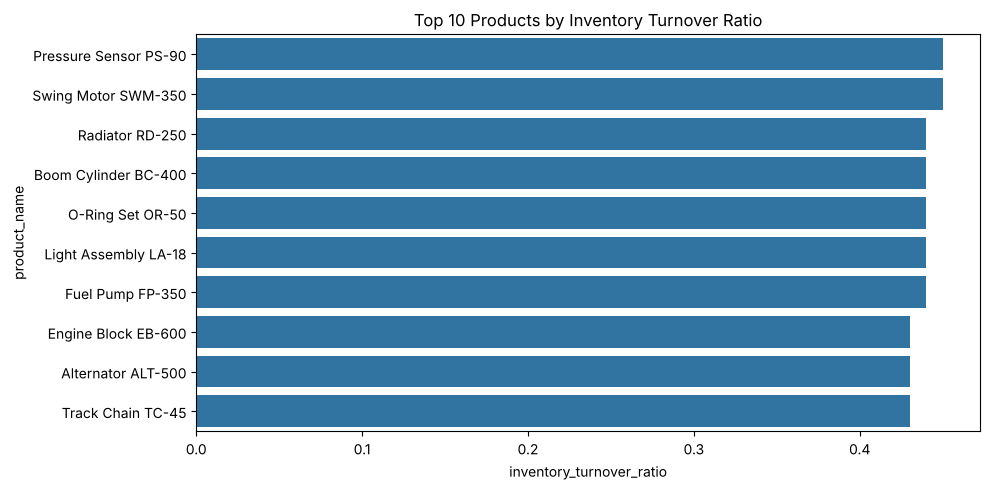

In [16]:
import seaborn as sns

fig, ax = plt.subplots(figsize=(10, 5))
top_turnover = inventory_kpi.sort_values("inventory_turnover_ratio", ascending=False).head(10)
sns.barplot(data=top_turnover, x="inventory_turnover_ratio", y="product_name", ax=ax)
ax.set_title("Top 10 Products by Inventory Turnover Ratio")
plt.tight_layout()
plt.show()

---
# Part C — Supplier KPIs

**Supplier data was previously missing from this dataset entirely.** Root cause: the raw
`purchase_orders_header` table has no `product_id`, so the only valid path from a product to its
supplier is `purchase_orders_lines` (has `product_id`) → `purchase_orders_header` (has
`supplier_id`) → `suppliers`. This join existed in an earlier revision of the Week 2 merge
notebook but was never carried into the final table, and was dropped from the notebook entirely
in a later revision. The dataset has since been rebuilt from the 10 raw source tables with this
join included — each product's supplier is assigned from its most recent purchase order.

In [17]:
supplier_columns_present = [c for c in inv_df.columns if "supplier" in c.lower()]
print("Supplier-related columns found:", supplier_columns_present)
print(f"supplier_id populated: {inv_df['supplier_id'].notna().sum():,} / {len(inv_df):,} rows")

Supplier-related columns found: ['supplier_id', 'supplier_name', 'supplier_type', 'supplier_city', 'supplier_province', 'supplier_region', 'supplier_pincode', 'supplier_lead_time_days']
supplier_id populated: 130,402 / 130,402 rows


## C.1 Supplier mix — revenue, order lines, and products supplied per supplier

In [18]:
supplier_mix = inv_df.groupby(["supplier_id", "supplier_name", "supplier_type"]).agg(
    order_lines=("so_id", "count"),
    products_supplied=("product_id", "nunique"),
    total_line_revenue=("line_grand_total", "sum"),
).round(2).sort_values("total_line_revenue", ascending=False)
supplier_mix

,,,order_lines,products_supplied,total_line_revenue
supplier_id,supplier_name,supplier_type,,,
SUP0007,Suzhou Local Vendor Supplies,Local Vendor,47634,11,1.110338e+10
SUP0004,Ningbo Distributor Supplies,Distributor,17486,4,1.096693e+10
SUP0001,Shenzhen OEM Supplies,OEM,30326,7,4.527168e+09
SUP0002,Guangzhou Local Vendor Supplies,Local Vendor,13095,3,2.895402e+09
SUP0005,Tianjin OEM Supplies,OEM,8786,2,2.133710e+09
SUP0006,Qingdao Distributor Supplies,Distributor,8672,2,7.186544e+08
SUP0003,Shanghai Distributor Supplies,Distributor,4403,1,7.950675e+07


## C.2 Exploratory chart: supplier revenue mix

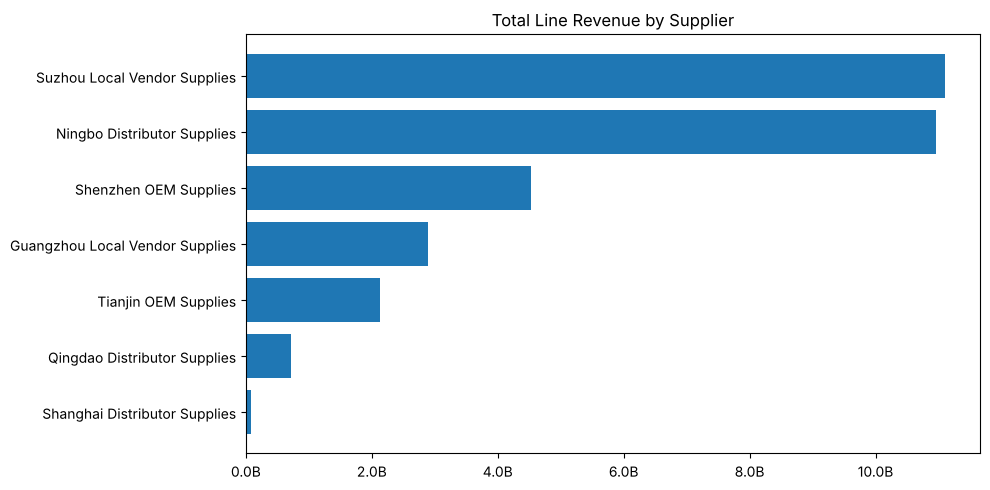

In [19]:
fig, ax = plt.subplots(figsize=(10, 5))
chart_data = supplier_mix.reset_index().sort_values("total_line_revenue", ascending=True)
ax.barh(chart_data["supplier_name"], chart_data["total_line_revenue"])
ax.set_title("Total Line Revenue by Supplier")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e9:.1f}B"))
plt.tight_layout()
plt.show()

---
## Summary for sprint notes

**Sales/customer:**
- Total revenue (2019–2024): ₹32.4B across 20,000 orders, essentially flat year-over-year
- Government and Corporate customers generate the most revenue
- South and West regions = ~68% of total revenue
- Average delivery lead time: 8.06 days, consistent across regions
- Top 2 products = ~36% of line revenue
- 61.3% Paid, 17.9% Partially Paid, 11.8% Not Invoiced, 9.0% Unpaid

**Product/inventory:**
- Inventory turnover ratio tightly clustered (0.40–0.45) across all 30 products
- Stock health: ~51% Optimal, ~24% Low Stock, ~24% Overstock (pending scale confirmation)
- `current_stock` vs. `max_stock` scale mismatch needs Data Analyst confirmation before the
  stock health KPI can be finalized

**Supplier:**
- Supplier gap resolved — supplier fields now populated on 100% of rows
- 7 of 8 suppliers are currently matched to at least one tracked product
- Suzhou Local Vendor Supplies and Ningbo Distributor Supplies account for the largest share of
  line revenue; full breakdown in `kpi_supplier_mix.csv`
- Supplier assigned via each product's most recent purchase order 